## NVIDIA NeMo Sortformer speaker diarization model
### (code to export as ONNX, quantize to int8, shrink model weights, and perform ONNX inference)

You may get Sortformer onnx model from

https://huggingface.co/altunenes/parakeet-rs/resolve/main/diar_streaming_sortformer_4spk-v2.1.onnx?download=true

The author may have exported it using the following script:

https://github.com/altunenes/parakeet-rs/blob/38fe0f51db64fc46c43f84f585cc262d0a7c9a92/scripts/export_diar_sortformer.py

In [ ]:
# NOTE:
# For shrinking of onnx models sizes RUN THE FOLLOWING COMMAND
# !pip install onnx-shrink-ray==0.0.9
#
# IMPORTANT INFO:
# Afterwards, when converting a bug may appear in form of
#           shrink.py", line 36, in gather_initializers_in_graph
#           graph.initializer.clear()
#           AttributeError: 'google._upb._message.RepeatedCompositeContainer' object has no attribute 'clear'
# To solve you may need to open
#     miniconda3/envs/your_conda_env/lib/python3.10/site-packages/onnx_shrink_ray/shrink.py
# and REPLACE LINE 36, which is
#       graph.initializer.clear()
# WITH the following
#       del graph.initializer[:]

### Quantize to int8

In [ ]:
import onnx
import torch
from onnxruntime.quantization import QuantFormat, QuantType, quantize_static, quantize_dynamic

input_model_path = "diar_streaming_sortformer_4spk-v2.1.onnx"
output_model_path = "sf21.int8.onnx"   # 8 bit quantized version

quantize_dynamic(
        input_model_path,
        output_model_path,
        op_types_to_quantize=[
            'MatMul', 'Gemm',
            #'Conv',
            'Add', 'Mul'
        ],
        weight_type=QuantType.QInt8
    )


### Shrink model weights

In [3]:
#!pip install onnx_shrink_ray
!python -m onnx_shrink_ray.shrink sf21.int8.shrink.onnx

### ONNX inference

In [ ]:
import onnxruntime as ort

session = ort.InferenceSession("sf21.int8.shrink.onnx")

#### Feature computation (NOTE: 128 num_mels is used when calling melscale_fbanks)

In [30]:
from onnxscript import opset17 as op
from onnx import TensorProto
import librosa
import numpy as np
import torchaudio

def normalize(x, lens):
    lens_3d = op.Unsqueeze(lens, [1, 2])
    mask = op.Range(0, op.Shape(x, start=2, end=3), 1) < lens_3d
    lens_3d = op.CastLike(lens_3d, x)
    mean = op.ReduceSum(op.Where(mask, x, 0), axes=[-1], keepdims=1) / lens_3d
    var = op.ReduceSumSquare(op.Where(mask, x - mean, 0), axes=(-1,), keepdims=1) / (lens_3d - 1)
    return op.Where(mask, (x - mean) / (op.Sqrt(var) + 1e-5), 0)

# TODO: check if we need to normalize chunk too
def compute_mel(waveforms):
    sample_rate = 16_000
    n_fft = 512
    win_length = 400
    hop_length = 160
    preemph = 0.97
    log_zero_guard_value = float(2**-24)

    melscale_fbanks = torchaudio.functional.melscale_fbanks(
        n_fft // 2 + 1, 0, sample_rate // 2, 128, sample_rate, "slaney", "slaney"
    ).numpy()

    waveforms = librosa.effects.preemphasis(waveforms)
    #waveforms = librosa.util.normalize(waveforms, norm=np.inf)  # <<-- crucial
    waveforms_lens = np.expand_dims(waveforms.shape[0], axis=0)
    waveforms = np.expand_dims(waveforms, axis=0)

    waveforms = op.Pad(
        waveforms,
        pads=op.Constant(value=[0, n_fft // 2, 0, n_fft // 2]),
        mode="reflect",
    )
    hann_window = op.Pad(
        op.HannWindow(win_length, periodic=0, output_datatype=TensorProto.DOUBLE),
        pads=op.Constant(value=[n_fft // 2 - win_length // 2, n_fft // 2 - win_length // 2]),
    )
    image = op.STFT(op.CastLike(waveforms, hann_window), hop_length, hann_window)
    spectrogram = op.ReduceSumSquare(image, axes=(-1,), keepdims=0)

    mel_spectrogram = op.MatMul(op.CastLike(spectrogram, melscale_fbanks), melscale_fbanks)
    log_mel_spectrogram = op.Log(mel_spectrogram + log_zero_guard_value)

    features_lens = np.int64(waveforms_lens / hop_length + 1)
    return op.Transpose(log_mel_spectrogram, perm=(0, 2, 1)), features_lens
    #return normalize(op.Transpose(log_mel_spectrogram, perm=(0, 2, 1)), features_lens), features_lens

#### Compute features for sample recording and do inference

In [ ]:
sample_rate = 16000

output_names = [
    "spkcache_fifo_chunk_preds",
    "chunk_pre_encode_embs",
    "chunk_pre_encode_lengths",
]

# compute log-mel spectrogram
waveform, _ = librosa.load("test1.wav", sr=sample_rate)
waveform_mod = waveform
mel, mel_lens = compute_mel(waveform_mod)
mel = mel.value.astype(np.float32)
mel = np.transpose(mel, axes=(0, 2, 1))

print(mel.shape)
print(waveform_mod.shape)

# mel value is shifted by 10ms, so mel.shape[1]=100 would mean 1 second of audio

my_win_len = 5.0    # in seconds
my_win_len_mels = int(my_win_len / 0.010)

mel_trunc_len = my_win_len_mels

mel = mel[:,0:mel_trunc_len,:]

chunk_len = mel_trunc_len

#print(mel.shape)

input_feed = {
    "chunk": mel,
    "chunk_lengths": np.array([chunk_len], np.int64), # 124
    "spkcache": np.ndarray((1, 0, 512), np.float32),
    "spkcache_lengths": np.array([0], np.int64),  # 188
    "fifo": np.ndarray((1, 0, 512), np.float32),
    "fifo_lengths": np.array([0], np.int64),  # 124
}

import time

t0 = time.time_ns()
outputs = session.run(output_names, input_feed)
t1 = time.time_ns()
print((t1-t0)/1e9)

preds = outputs[0]
preds = preds[0]
print(preds.shape)
#print(spkcache_fifo_chunk_preds.shape)

(1, 2992, 128)
(478640,)
0.072626455
(63, 4)


#### Plot Sortformer output

(63, 4)


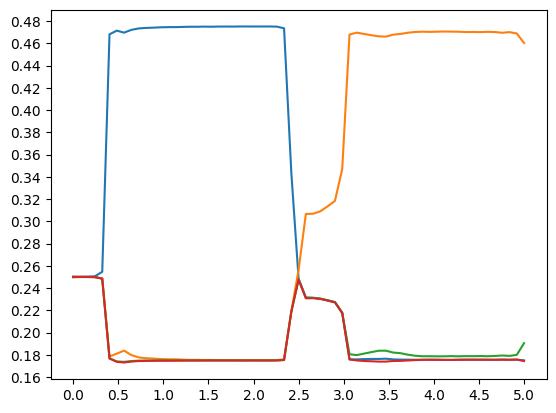

In [ ]:
import torch
import torch.nn.functional as F

output = torch.tensor(preds)

# convert logits to softmax values
output = F.softmax(output, dim=1).numpy()

print(output.shape)

import matplotlib.pyplot as plt
plt.figure()
plt.locator_params(nbins=20)
plt.plot(np.linspace(0, my_win_len, output.shape[0]), output)